# Módulo 2 — Tendência e sazonalidade

## Seção 5 — Estimação conjunta de tendência e sazonalidade por mínimos quadrados

**Estado editorial:** seção autônoma para revisão. **Integração:** fundamentação, dedução, exemplo numérico, Python, figura e exercícios no próprio texto.  
**Pré-requisitos:** Seção 1 (tendência e MQO), Seção 2 (sazonalidade), Seção 3 (dummies e restrições de identificação), Seção 4 (suavização e seus limites); operações elementares com vetores e matrizes.  
**Fontes acadêmicas efetivamente consultadas:** MORETTIN; TOLOI, *Análise de séries temporais: modelos lineares univariados*, v. 1, 3ª ed., cap. 3, §3.2.2, pp. 55–56 e §3.3, p. 68 (equações (3.35)–(3.37)). A formulação aditiva $Z_t=T_t+S_t+a_t$ e a subtração do efeito sazonal estimado são fundamentadas nessa obra. **A derivação matricial detalhada, os números, o código e o estudo conjunto de MQO são complementações didáticas originais**, construídos a partir dos métodos das seções anteriores.  
**Mapeamento audiovisual:** bloco C, aulas *Método dos Mínimos Quadrados: Tendência* (1–4) e *Método dos Mínimos Quadrados: Sazonalidade* (1–7).

### Objetivos de aprendizagem

Você deverá conseguir: (a) justificar por que tendência e sazonalidade precisam ser consideradas em conjunto; (b) construir a matriz de regressão sem multicolinearidade perfeita; (c) deduzir as equações normais; (d) calcular um exemplo manual; (e) recuperar intercepto e efeitos sazonais com soma zero; (f) interpretar resíduos e uma série dessazonalizada; (g) implementar o ajuste com `numpy.linalg.lstsq`; (h) reconhecer limitações de inferência e riscos de vazamento temporal.

### 1. O problema de atribuição: o que é tendência e o que é sazonalidade?

Considere o modelo aditivo

$$
\boxed{Z_t=\alpha+\beta t+S_t+\varepsilon_t,\qquad S_{t+4}=S_t.}
$$

A tendência é $T_t=\alpha+\beta t$ e a sazonalidade possui quatro efeitos. Se $\beta>0$, o terceiro trimestre de um ano ocorre mais tarde que o primeiro e pode ter valor maior **mesmo sem** um efeito sazonal maior. Calcular simplesmente as médias por trimestre, sem controlar a tendência, pode confundir posição no calendário com crescimento temporal.

A ideia é estimar $\alpha$, $\beta$ e os efeitos sazonais em **um único problema** de mínimos quadrados. Isso permite decompor a média estimada em parte tendencial e parte sazonal, respeitando as hipóteses do modelo.

### 2. Parametrização identificável por indicadores

Para $t=1,\ldots,N$, seja $q(t)\in\{1,2,3,4\}$ a posição trimestral, e defina $D_{j,t}=1$ se $q(t)=j$ e zero caso contrário. Usaremos o quarto trimestre como **categoria de referência**:

$$
\boxed{Z_t=b_0+b_1t+\delta_1D_{1,t}+\delta_2D_{2,t}+\delta_3D_{3,t}+\varepsilon_t.}
$$

Aqui $b_0+b_1t$ representa a média do quarto trimestre no instante $t$; $\delta_j$ é a diferença de nível do trimestre $j$ em relação ao quarto. A escolha de referência é convenção matemática: não significa que o quarto trimestre seja especial fisicamente.

Por que não incluir simultaneamente intercepto e quatro indicadoras? Porque

$$
1=D_{1,t}+D_{2,t}+D_{3,t}+D_{4,t}
$$

para todo $t$. A coluna do intercepto seria combinação linear das quatro colunas sazonais. Remover uma indicadora é uma forma de tornar o modelo identificável; a outra, desenvolvida na Seção 3, é manter quatro efeitos impondo soma zero.

### 3. Da soma de quadrados às equações normais

Organizamos os dados observados em um vetor $\mathbf z\in\mathbb R^N$ e os regressores em uma matriz $\mathbf X\in\mathbb R^{N\times5}$. A linha referente ao instante $t$ é

$$
\mathbf x_t=(1,\ t,\ D_{1,t},\ D_{2,t},\ D_{3,t}).
$$

Com $\boldsymbol\theta=(b_0,b_1,\delta_1,\delta_2,\delta_3)^\top$, temos

$$
\mathbf z=\mathbf X\boldsymbol\theta+\boldsymbol\varepsilon.
$$

O critério dos mínimos quadrados é

$$
Q(\boldsymbol\theta)=\|\mathbf z-\mathbf X\boldsymbol\theta\|_2^2
=(\mathbf z-\mathbf X\boldsymbol\theta)^\top
(\mathbf z-\mathbf X\boldsymbol\theta).
$$

Expandindo o produto e lembrando que $\mathbf z^\top\mathbf X\boldsymbol\theta$ é um escalar,

$$
Q=\mathbf z^\top\mathbf z-2\boldsymbol\theta^\top\mathbf X^\top\mathbf z
+\boldsymbol\theta^\top\mathbf X^\top\mathbf X\boldsymbol\theta.
$$

Derivando em relação ao vetor de parâmetros,

$$
\nabla_{\boldsymbol\theta} Q
=-2\mathbf X^\top\mathbf z+2\mathbf X^\top\mathbf X\boldsymbol\theta.
$$

Igualando a zero, obtemos as **equações normais**:

$$
\boxed{\mathbf X^\top\mathbf X\widehat{\boldsymbol\theta}=\mathbf X^\top\mathbf z.}
$$

Se $\mathbf X$ tiver posto coluna completo (neste caso, posto 5), então $\mathbf X^\top\mathbf X$ será invertível e o minimizador único poderá ser escrito matematicamente como

$$
\widehat{\boldsymbol\theta}=(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top\mathbf z.
$$

**Computacionalmente, não formaremos essa inversa.** Em geral, `np.linalg.lstsq` resolve o problema com métodos numéricos mais estáveis. Se faltarem trimestres inteiros ou a matriz possuir colunas dependentes, a identificação deverá ser reconsiderada. A existência da solução de MQO não garante que os pressupostos usados para testes estatísticos sejam verdadeiros.

### 4. Exemplo resolvido: 12 observações trimestrais

Construiremos **dados sintéticos**, com tendência, padrão sazonal e uma pequena perturbação intencional:

$$
Z_t=30+2t+S_t+r_t,
\qquad
(S_1,S_2,S_3,S_4)=(-3,1,4,-2).
$$

Para os doze instantes, estabelecemos

$$
(r_1,\ldots,r_{12})=(1,-1,0,0,-2,2,0,0,1,-1,0,0).
$$

A tabela calculada a partir dessa expressão é:

| Ano | T1 | T2 | T3 | T4 |
|---|---:|---:|---:|---:|
| 1 | 30 | 34 | 40 | 36 |
| 2 | 35 | 45 | 48 | 44 |
| 3 | 46 | 50 | 56 | 52 |

**Atenção:** $r_t$ é uma sequência numérica construída; não estamos afirmando que seja uma realização observada de um mecanismo probabilístico conhecido. A tabela permite verificar a álgebra dos mínimos quadrados.

#### 4.1 O erro de ignorar a tendência

Se calculássemos simplesmente as médias por trimestre, obteríamos

$$
(\overline z_1,\overline z_2,\overline z_3,\overline z_4)=(37,43,48,44).
$$

A média dessas quatro quantidades é $43$, de modo que os supostos efeitos sazonais centrados seriam

$$
(-6,0,5,1),
$$

que são **diferentes** dos efeitos $(-3,1,4,-2)$ presentes na construção dos dados. O erro surge porque cada trimestre corresponde a instantes distintos, em uma série crescente.

#### 4.2 Solução conjunta por mínimos quadrados

No modelo de referência do quarto trimestre, os coeficientes ajustados são

$$
\boxed{(\widehat b_0,\widehat b_1,\widehat\delta_1,\widehat\delta_2,\widehat\delta_3)
=(28,2,-1,3,6).}
$$

Podemos conferir a parametrização para o primeiro trimestre:

$$
\widehat Z_1=28+2(1)-1=29,
$$

com observação $z_1=30$ e resíduo $r_1=1$. Para o quarto trimestre, que serve como referência,

$$
\widehat Z_4=28+2(4)=36=z_4.
$$

**Por que esses coeficientes minimizam a soma de quadrados?** No exemplo, o vetor $\mathbf r$ foi construído para ser ortogonal às cinco colunas de $\mathbf X$:

$$
\sum_{t=1}^{12}r_t=0,\qquad
\sum_{t=1}^{12}t r_t=0,\qquad
\sum_{t:q(t)=j}r_t=0\quad(j=1,2,3).
$$

Logo, $\mathbf X^\top\mathbf r=\mathbf0$. Como $\mathbf z=\mathbf X\boldsymbol\theta+\mathbf r$, segue

$$
\mathbf X^\top\mathbf z=\mathbf X^\top\mathbf X\boldsymbol\theta,
$$

isto é, $\boldsymbol\theta$ satisfaz as equações normais. Como a matriz possui posto coluna 5, essa solução é única. Trata-se de uma verificação **exata do exemplo algébrico**, independente de simulação.

### 5. Convertendo a categoria de referência para soma zero

O modelo anterior atribui ao quarto trimestre efeito zero e aos demais os coeficientes $(-1,3,6)$. Para comparar com a parametrização anterior $Z_t=\alpha+\beta t+S_t+\varepsilon_t$, com soma sazonal nula, escrevemos os efeitos brutos

$$
\mathbf d=(-1,3,6,0).
$$

Sua média é $\overline d=(-1+3+6+0)/4=2$. Definimos

$$
\widehat S_j=d_j-\overline d.
$$

Assim,

$$
\boxed{(\widehat S_1,\widehat S_2,\widehat S_3,\widehat S_4)=(-3,1,4,-2),}
$$

e o intercepto da função média não sazonal é

$$
\widehat\alpha=\widehat b_0+\overline d=28+2=30.
$$

Recuperamos a tendência estimada $\widehat T_t=30+2t$. A transferência de uma constante dos efeitos sazonais para o intercepto **não modifica os valores ajustados**; apenas muda a convenção de parametrização. Com intercepto e tendência, a restrição de soma zero identifica o nível médio ao longo do ciclo, mas $\alpha$ não é necessariamente a média das observações em todo o intervalo porque a tendência varia com $t$.

### 6. Série dessazonalizada e resíduos: não confundir os objetos

Uma vez estimados os efeitos, definimos a série **dessazonalizada aditiva**:

$$
\boxed{Z_t^{SA}=Z_t-\widehat S_t.}
$$

Esse procedimento corresponde à ideia de ajuste sazonal de Morettin e Toloi, §3.3, p. 68, equação (3.35). No nosso exemplo, o valor dessazonalizado no instante 1 é $30-(-3)=33$. A tendência ajustada nesse instante é $\widehat T_1=32$; resta a perturbação $r_1=1$.

Já o resíduo do **modelo completo** é

$$
\boxed{\widehat\varepsilon_t=Z_t-\widehat T_t-\widehat S_t.}
$$

Logo, **dessazonalizar não é o mesmo que remover tendência e sazonalidade**. O primeiro procedimento deixa a tendência e o resíduo; o segundo deixa somente o resíduo ajustado. Também não devemos supor automaticamente que resíduos tenham independência, variância constante ou distribuição normal: precisam ser diagnosticados, com métodos estudados mais adiante.

O livro também descreve a forma multiplicativa $Z_t=T_tS_ta_t$, com ajuste por divisão $Z_t^{SA}=Z_t/\widehat S_t$ quando $\widehat S_t\neq0$. Neste módulo trabalharemos principalmente com a formulação **aditiva**, para não antecipar o estudo completo de decomposição e transformação de escala do Módulo 6.

### 7. Python integrado — construindo a matriz e resolvendo MQO

O código a seguir reproduz **todos os coeficientes do exemplo**. Requer Python 3.10 ou posterior e NumPy. É importante entender como cada coluna de `X` corresponde à equação matemática.

In [ ]:
import numpy as np

t = np.arange(1, 13, dtype=float)
trimestre = (t.astype(int) - 1) % 4  # 0, 1, 2, 3
sazonal = np.array([-3., 1., 4., -2.])
residuo_construido = np.array(
    [1., -1., 0., 0., -2., 2., 0., 0., 1., -1., 0., 0.]
)

# Dados sintéticos: nível + tendência + sazonalidade + perturbação
z = 30 + 2 * t + sazonal[trimestre] + residuo_construido

# Intercepto, tempo, indicadores dos trimestres 1, 2 e 3
X = np.column_stack([
    np.ones(len(t)),
    t,
    (trimestre == 0).astype(float),
    (trimestre == 1).astype(float),
    (trimestre == 2).astype(float),
])

coeficientes, *_ = np.linalg.lstsq(X, z, rcond=None)
ajuste = X @ coeficientes
residuos = z - ajuste

print(np.round(coeficientes, 6))  # [28.  2. -1.  3.  6.]
print(np.linalg.matrix_rank(X))  # 5


**O que cada operação faz?** `np.arange` cria os instantes; `% 4` encontra a posição no ciclo; a expressão booleana `trimestre == 0` sinaliza o primeiro trimestre; `.astype(float)` converte falso/verdadeiro em 0/1; `np.column_stack` monta a matriz com cinco colunas; `np.linalg.lstsq` estima o vetor que minimiza a soma dos quadrados; `X @ coeficientes` efetua o produto matricial; `np.linalg.matrix_rank` verifica o posto numérico.

Para recuperar a parametrização com soma sazonal zero:

In [ ]:
efeitos_brutos = np.r_[coeficientes[2:], 0.]
efeitos_centrados = efeitos_brutos - efeitos_brutos.mean()
intercepto_centrado = coeficientes[0] + efeitos_brutos.mean()

print(np.round(efeitos_centrados, 6))  # [-3.  1.  4. -2.]
print(round(intercepto_centrado, 6))   # 30.0


O operador `np.r_` concatena os três contrastes e o zero da categoria de referência. A operação `efeitos_brutos.mean()` calcula a média dos quatro efeitos brutos; subtraí-la centraliza os efeitos, enquanto somá-la ao intercepto mantém a mesma média ajustada.

Para reproduzir também o gráfico, execute o script complementar `modulo_02_secoes_05_exemplos.py`:

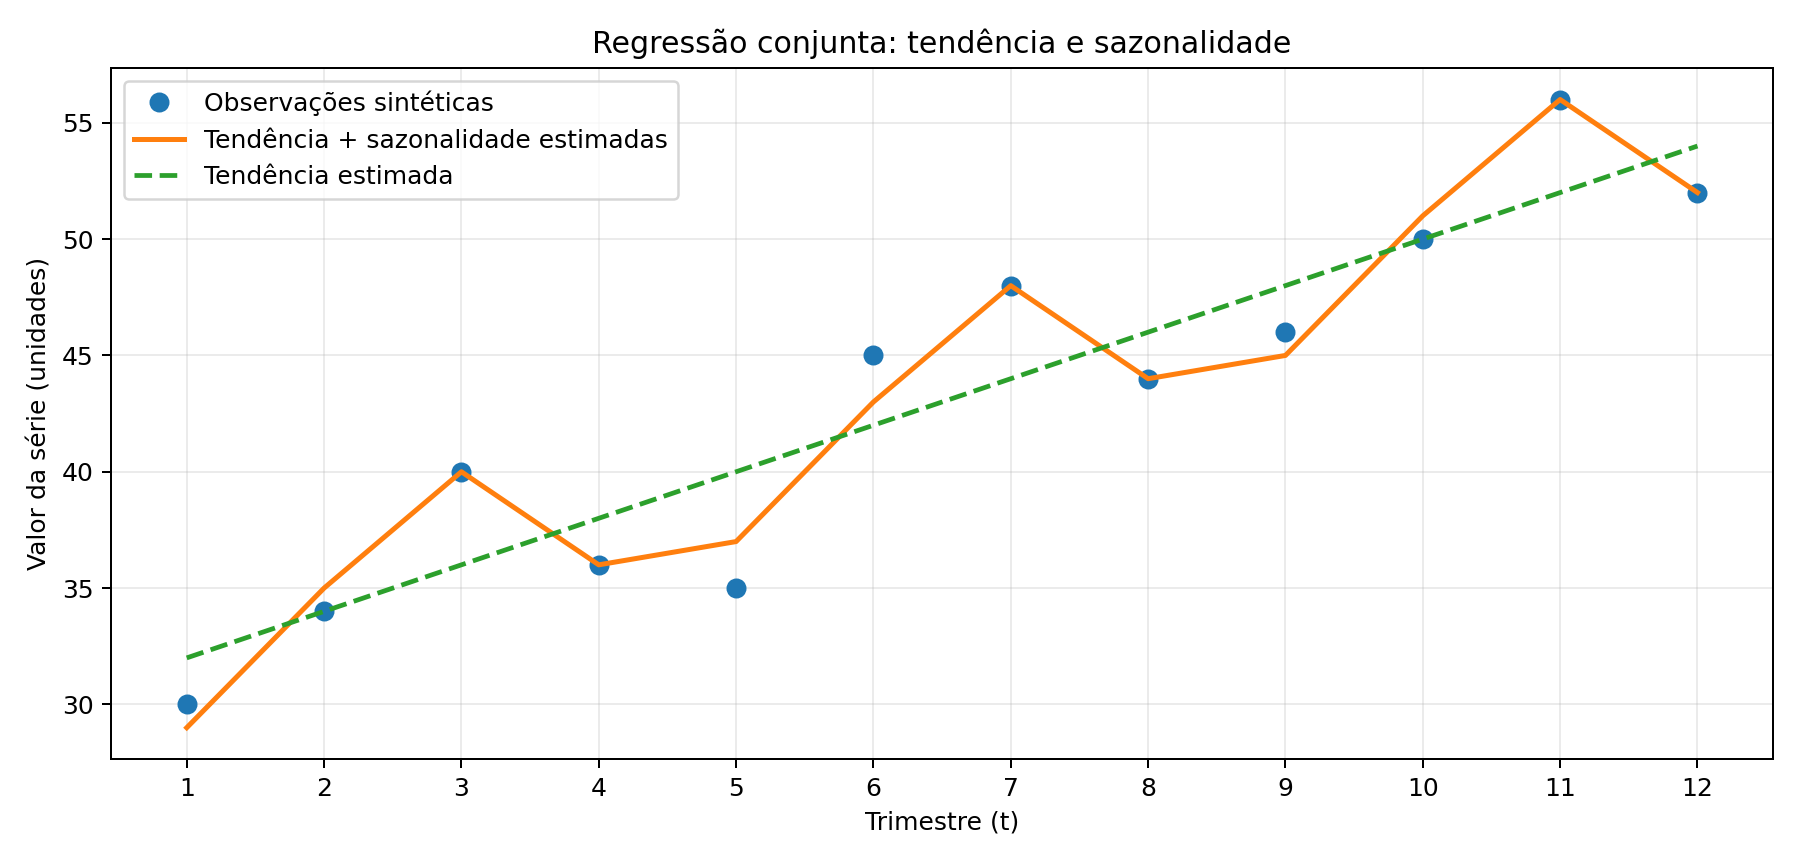

*Figura 5.1 — Dados trimestrais sintéticos, regressão conjunta por indicadores e tendência linear estimada. As oscilações em torno da reta não representam apenas ruído: parte delas corresponde ao componente sazonal. O ajuste reproduz os coeficientes construídos no exemplo, sem validar automaticamente o modelo para dados reais.*

**Verificação computacional:** os coeficientes retornaram $(28,2,-1,3,6)$, os efeitos centrados $(-3,1,4,-2)$ e o intercepto $30$. As equações normais foram conferidas até tolerância numérica compatível com ponto flutuante. Isso é uma verificação de implementação, não um teste estatístico de adequação.

### 8. E se usarmos seno e cosseno?

Na Seção 3, construímos sazonalidade por componentes harmônicas. Também poderíamos estimar tendência e harmônicas conjuntamente:

$$
Z_t=\alpha+\beta t+
\sum_{k=1}^{K}\left[
 a_k\cos\left(\frac{2\pi kt}{s}\right)
+b_k\sin\left(\frac{2\pi kt}{s}\right)
\right]+\varepsilon_t,
$$

incluindo a componente de Nyquist adequada quando $s$ for par e a representação for completa. A resolução numérica continua sendo um problema de MQO, porque os regressores seno e cosseno são **funções conhecidas de $t$**, embora sejam não lineares em $t$. A linearidade do modelo refere-se aos coeficientes desconhecidos, não à forma de cada função de tempo.

Uma única harmônica pode ser uma representação mais econômica, mas menos flexível, que um conjunto completo de indicadores. A comparação detalhada das frequências e da Transformada de Fourier continuará reservada aos módulos espectrais.

### 9. Limitações e cuidados científicos

- **Especificação:** a tendência pode não ser linear e os efeitos sazonais podem mudar com o tempo. Um ajuste aparentemente bom não prova que essas hipóteses sejam verdadeiras.
- **Identificação:** intercepto e todas as indicadoras simultaneamente geram dependência linear; para uma matriz de regressão estimável, é indispensável parametrização adequada.
- **Inferência:** MQO calcula estimativas mesmo com erros autocorrelacionados, mas inferências usuais que ignoram a dependência podem produzir erros-padrão e testes incorretos.
- **Amostra pequena:** doze observações fornecem pouco suporte para diagnosticar sazonalidade e mudanças estruturais; este é um exemplo de álgebra, não um estudo empírico.
- **Validação temporal:** para avaliar previsão, estimar tendência e sazonalidade apenas no intervalo de treinamento e aplicar ao futuro o modelo já ajustado. Usar informações do período de teste para estimar os efeitos provoca vazamento temporal.
- **Interpretação da precipitação:** zeros medidos são diferentes de dados ausentes; efeitos sazonais aditivos podem ser inadequados para séries com muitos zeros, forte assimetria e variação de dispersão. Essa escolha demanda diagnóstico e alternativas em módulos posteriores.

### 10. Exercícios

**Conceitual.** Por que, em uma série crescente, a média simples das observações de cada trimestre pode não estimar corretamente o efeito sazonal? Utilize os valores do exemplo.

**Matricial.** Escreva explicitamente as quatro primeiras linhas de $\mathbf X$ e verifique que o modelo possui cinco coeficientes. Qual coluna seria redundante se acrescentássemos uma quarta indicadora?

**Numérico.** Com os coeficientes $(28,2,-1,3,6)$, obtenha os valores ajustados de $Z_1$ e $Z_2$, os resíduos respectivos e a série dessazonalizada nesses dois instantes.

**Demonstração.** Prove que subtrair a média dos quatro contrastes sazonais e adicioná-la ao intercepto mantém $\widehat Z_t$ inalterado para qualquer trimestre.

**Programação orientada.** Modifique o código para 16 trimestres. Antes de executar, descreva como construirá a matriz de indicadores para evitar erro de alinhamento. Compare os coeficientes ao introduzir uma mudança de inclinação após o oitavo trimestre. Explique por que um modelo linear único pode deixar resíduos sistemáticos.

**Pesquisa aplicada.** Esboce um protocolo para avaliar uma regressão sazonal em dados de precipitação: verificação de calendário regular, tratamento explícito de ausências, divisão cronológica, diagnóstico residual e interpretação dos coeficientes. Não transforme registros faltantes em precipitação zero.

**Resultados selecionados:** no exercício numérico, $\widehat Z_1=29$, $\widehat Z_2=35$, resíduos $1$ e $-1$, e valores dessazonalizados $33$ e $33$. No exercício matricial, as linhas são $(1,1,1,0,0)$, $(1,2,0,1,0)$, $(1,3,0,0,1)$ e $(1,4,0,0,0)$; a indicadora do quarto trimestre seria redundante.

### 11. Síntese e referências

O ajuste conjunto permite separar tendência e sazonalidade sem tratar cada componente isoladamente. A regressão por indicadores pode ser formulada matricialmente e resolvida por mínimos quadrados, desde que a parametrização seja identificável. A dessazonalização subtrai $\widehat S_t$, enquanto o resíduo completo subtrai também $\widehat T_t$. A interpretação científica exige diagnósticos e respeito à ordem temporal.

**Bibliografia acadêmica consultada:** MORETTIN, Pedro A.; TOLOI, Clélia M. C. *Análise de séries temporais: modelos lineares univariados*. 3. ed. São Paulo: Blucher, 2018. v. 1. Cap. 3, §§3.2.2 e 3.3, em especial p. 68, eqs. (3.35)–(3.37).  
**Catálogo pedagógico consultado:** `mapeamento-conteudos-series-temporais.md`, bloco C, aulas de mínimos quadrados para tendência e sazonalidade.  
**Complementações originais:** formulação conjunta das indicadoras com tendência, dedução matricial, sequência sintética, solução demonstrada por ortogonalidade, reparametrização, scripts, figura e exercícios.